# Module 3 — Phase 3: EfficientNet-B0 Tampering Classifier
**AI Passport Screening System — India → Bangladesh Border Checkpoint**

> **Important:** This notebook requires the Phase 2 labeled dataset.  
> If Phase 2 has not been completed, the preflight cell will stop execution with a clear message.
>
> Classifier output scores are model softmax values — NOT calibrated fraud probabilities.

## Cell 1 — Imports and Project Path

In [1]:
import sys, os, json

# ── Project root (one level up from notebooks/) ───────────────────────────────
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import torch
print('PyTorch version :', torch.__version__)
print('CUDA available  :', torch.cuda.is_available())
print('Project root    :', PROJECT_ROOT)

PyTorch version : 2.14.0+cpu
CUDA available  : False
Project root    : C:\Users\priya\Desktop\prototype


## Cell 2 — Configuration (edit paths here)

In [2]:
# ── EDIT THESE PATHS ──────────────────────────────────────────────────────────

# Phase 2 dataset root  (must contain genuine/ and tampered/ sub-folders
#                        OR a manifest.csv — created by Phase 2)
DATASET_ROOT = os.path.join(PROJECT_ROOT, 'data', 'tampering_dataset')

# Where to save model checkpoints and training config
CHECKPOINT_DIR = os.path.join(PROJECT_ROOT, 'data', 'model_checkpoints', 'efficientnet_b0')

# Where to save evaluation results (JSON + CSV)
EVAL_OUTPUT_DIR = os.path.join(PROJECT_ROOT, 'data', 'evaluation_results', 'phase3')

# Single passport image for inference demo
INFERENCE_IMAGE = os.path.join(PROJECT_ROOT, 'passport', 'passport1.jpg')

# Training hyper-parameters (change as needed)
CFG = dict(
    train_ratio      = 0.70,
    val_ratio        = 0.15,
    seed             = 42,
    pretrained       = True,
    freeze_backbone  = True,
    unfreeze_after   = 5,     # epoch to unfreeze backbone; set None to keep frozen
    lr               = 1e-4,
    batch_size       = 16,
    epochs           = 20,
    patience         = 5,
    weight_decay     = 1e-4,
    use_weighted_sampler = True,
)

print('Dataset root    :', DATASET_ROOT)
print('Checkpoint dir  :', CHECKPOINT_DIR)
print('Eval output dir :', EVAL_OUTPUT_DIR)
print('Inference image :', INFERENCE_IMAGE)

Dataset root    : C:\Users\priya\Desktop\prototype\data\tampering_dataset
Checkpoint dir  : C:\Users\priya\Desktop\prototype\data\model_checkpoints\efficientnet_b0
Eval output dir : C:\Users\priya\Desktop\prototype\data\evaluation_results\phase3
Inference image : C:\Users\priya\Desktop\prototype\passport\passport1.jpg


## Cell 3 — Dataset Readiness Check
⛔ **Execution stops here if Phase 2 dataset is missing.**

In [3]:
from app.tampering.dataset_loader import check_dataset_readiness

readiness = check_dataset_readiness(DATASET_ROOT)

print('Dataset root    :', readiness['dataset_root'])
print('Ready           :', readiness['ready'])
print('Has manifest    :', readiness['has_manifest'])
print('Genuine images  :', readiness['genuine_count'])
print('Tampered images :', readiness['tampered_count'])

if readiness['issues']:
    print('\n⚠️  ISSUES FOUND:')
    for issue in readiness['issues']:
        print(' •', issue)

if not readiness['ready']:
    raise RuntimeError(
        "\n\n"
        "========================================================\n"
        "  DATASET NOT READY — Training cannot proceed.\n"
        "  Phase 2 (Synthetic Tampering Dataset Generation)\n"
        "  must be completed before running this notebook.\n"
        "\n"
        f"  Expected dataset root: {DATASET_ROOT}\n"
        "  Required structure:\n"
        "    <dataset_root>/\n"
        "        genuine/<base_doc_id>/*.jpg\n"
        "        tampered/<base_doc_id>/*.jpg\n"
        "    OR: <dataset_root>/manifest.csv\n"
        "========================================================\n"
    )

print('\n✅ Dataset is ready — continuing...')

Dataset root    : C:\Users\priya\Desktop\prototype\data\tampering_dataset
Ready           : True
Has manifest    : True
Genuine images  : 13
Tampered images : 52

✅ Dataset is ready — continuing...


## Cell 4 — Load Dataset and Class Counts

In [4]:
from app.tampering.dataset_loader import load_dataset

ds = load_dataset(
    dataset_root = DATASET_ROOT,
    train_ratio  = CFG['train_ratio'],
    val_ratio    = CFG['val_ratio'],
    seed         = CFG['seed'],
)

if not ds['success']:
    for err in ds['errors']:
        print('ERROR:', err)
    raise RuntimeError('Dataset loading failed — see errors above.')

print('Source        :', ds['source'])
print('Class counts  :', ds['class_counts'])
print('Split counts  :', ds['split_counts'])

train_samples = ds['train']
val_samples   = ds['val']
test_samples  = ds['test']

Source        : manifest
Class counts  : {'GENUINE': 13, 'TAMPERED': 52}
Split counts  : {'train': 45, 'val': 10, 'test': 10}


## Cell 5 — Verify Grouped Split (no doc leakage)

In [5]:
train_ids = {s['base_document_id'] for s in train_samples}
val_ids   = {s['base_document_id'] for s in val_samples}
test_ids  = {s['base_document_id'] for s in test_samples}

tv_overlap  = train_ids & val_ids
tt_overlap  = train_ids & test_ids
vt_overlap  = val_ids   & test_ids

print(f'Train docs : {len(train_ids)} | Val docs: {len(val_ids)} | Test docs: {len(test_ids)}')
print(f'Train∩Val  : {tv_overlap}  (must be empty)')
print(f'Train∩Test : {tt_overlap}  (must be empty)')
print(f'Val∩Test   : {vt_overlap}  (must be empty)')

assert not tv_overlap, f'LEAKAGE: train/val share docs: {tv_overlap}'
assert not tt_overlap, f'LEAKAGE: train/test share docs: {tt_overlap}'
assert not vt_overlap, f'LEAKAGE: val/test share docs: {vt_overlap}'
print('\n✅ No document leakage across splits.')

Train docs : 9 | Val docs: 2 | Test docs: 2
Train∩Val  : set()  (must be empty)
Train∩Test : set()  (must be empty)
Val∩Test   : set()  (must be empty)

✅ No document leakage across splits.


## Cell 6 — Model Initialisation

In [6]:
from app.tampering.model import build_model, get_device, NUM_CLASSES, CLASS_NAMES

device = get_device()
print('Device      :', device)
print('Num classes :', NUM_CLASSES)
print('Labels      :', CLASS_NAMES)

model = build_model(
    pretrained      = CFG['pretrained'],
    freeze_backbone = CFG['freeze_backbone'],
)

total_params    = sum(p.numel() for p in model.parameters())
trainable_params= sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total params    : {total_params:,}')
print(f'Trainable params: {trainable_params:,}')

del model  # will be re-created inside train()

Device      : cpu
Num classes : 2
Labels      : {0: 'GENUINE', 1: 'TAMPERED'}
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\priya/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth


100%|█████████████████████████████████████████████████████████████████████████████| 20.5M/20.5M [00:07<00:00, 2.89MB/s]

Total params    : 4,010,110
Trainable params: 2,562


## Cell 7 — Training
⏳ This will take time depending on dataset size and hardware.

In [7]:
from app.tampering.train import train

train_result = train(
    train_samples    = train_samples,
    val_samples      = val_samples,
    checkpoint_dir   = CHECKPOINT_DIR,
    pretrained       = CFG['pretrained'],
    freeze_backbone  = CFG['freeze_backbone'],
    unfreeze_after   = CFG['unfreeze_after'],
    lr               = CFG['lr'],
    batch_size       = CFG['batch_size'],
    epochs           = CFG['epochs'],
    patience         = CFG['patience'],
    weight_decay     = CFG['weight_decay'],
    seed             = CFG['seed'],
    use_weighted_sampler = CFG['use_weighted_sampler'],
)

if train_result['errors']:
    for e in train_result['errors']:
        print('ERROR:', e)
    raise RuntimeError('Training failed.')

print(f"\nBest val_acc : {train_result['best_val_acc']:.4f}")
print(f"Best epoch   : {train_result['best_epoch']}")
print(f"Checkpoint   : {train_result['checkpoint_path']}")

Epoch   1/20  train_loss=0.6724  train_acc=0.5556  val_loss=0.6656  val_acc=0.6000  (3.0s)
  ✓ New best val_acc=0.6000 — checkpoint saved.
Epoch   2/20  train_loss=0.6872  train_acc=0.5778  val_loss=0.6851  val_acc=0.4000  (2.6s)
Epoch   3/20  train_loss=0.7099  train_acc=0.4667  val_loss=0.6638  val_acc=0.6000  (2.5s)
Epoch   4/20  train_loss=0.6885  train_acc=0.5778  val_loss=0.6599  val_acc=0.6000  (2.6s)
Epoch   5/20  train_loss=0.7298  train_acc=0.4000  val_loss=0.6563  val_acc=0.6000  (6.9s)
Epoch   6/20  train_loss=0.7092  train_acc=0.5111  val_loss=0.6503  val_acc=0.7000  (6.0s)
  ✓ New best val_acc=0.7000 — checkpoint saved.
Epoch   7/20  train_loss=0.7072  train_acc=0.4222  val_loss=0.6450  val_acc=0.8000  (5.7s)
  ✓ New best val_acc=0.8000 — checkpoint saved.
Epoch   8/20  train_loss=0.6974  train_acc=0.4222  val_loss=0.6352  val_acc=0.8000  (5.8s)
Epoch   9/20  train_loss=0.6858  train_acc=0.5111  val_loss=0.6463  val_acc=0.8000  (7.0s)
Epoch  10/20  train_loss=0.6800  trai

## Cell 8 — Training History Visualisation

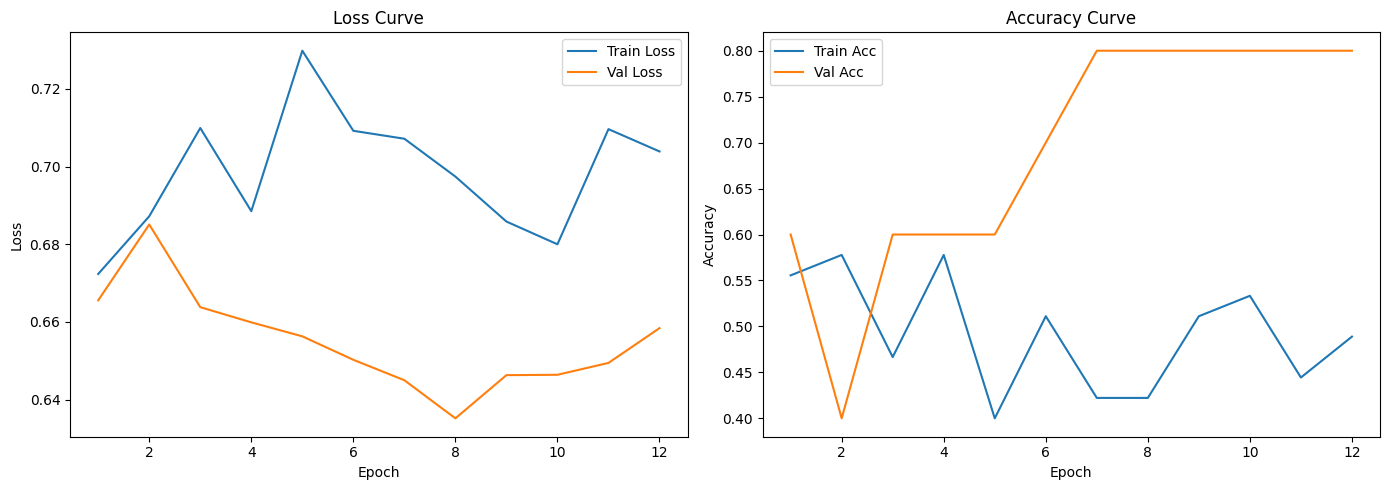

In [8]:
import matplotlib.pyplot as plt

history = train_result['history']
epochs_ran = [r['epoch']      for r in history]
train_loss = [r['train_loss'] for r in history]
val_loss   = [r['val_loss']   for r in history]
train_acc  = [r['train_acc']  for r in history]
val_acc    = [r['val_acc']    for r in history]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_ran, train_loss, label='Train Loss')
axes[0].plot(epochs_ran, val_loss,   label='Val Loss')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].set_title('Loss Curve'); axes[0].legend()

axes[1].plot(epochs_ran, train_acc, label='Train Acc')
axes[1].plot(epochs_ran, val_acc,   label='Val Acc')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].set_title('Accuracy Curve'); axes[1].legend()

plt.tight_layout()
plt.show()

## Cell 9 — Load Best Checkpoint

In [9]:
import os
from app.tampering.model import load_checkpoint

CHECKPOINT_PATH = train_result['checkpoint_path']  # auto from training
# Or override manually:
# CHECKPOINT_PATH = os.path.join(CHECKPOINT_DIR, 'best_checkpoint.pt')

ckpt = load_checkpoint(CHECKPOINT_PATH)
print('Loaded checkpoint:')
print('  Epoch   :', ckpt['epoch'])
print('  Val acc :', ckpt['val_acc'])
print('  Config  :', json.dumps(ckpt['config'], indent=4))

Loaded checkpoint:
  Epoch   : 7
  Val acc : 0.8
  Config  : {
    "pretrained": true,
    "freeze_backbone": true,
    "unfreeze_after": 5,
    "lr": 0.0001,
    "batch_size": 16,
    "epochs": 20,
    "patience": 5,
    "weight_decay": 0.0001,
    "seed": 42,
    "use_weighted_sampler": true,
    "input_size": [
        224,
        224
    ],
    "imagenet_mean": [
        0.485,
        0.456,
        0.406
    ],
    "imagenet_std": [
        0.229,
        0.224,
        0.225
    ],
    "num_classes": 2,
    "device": "cpu",
    "train_samples": 45,
    "val_samples": 10
}


## Cell 10 — Held-Out Test Evaluation

In [10]:
from app.tampering.evaluate import evaluate

eval_result = evaluate(
    test_samples    = test_samples,
    checkpoint_path = CHECKPOINT_PATH,
    output_dir      = EVAL_OUTPUT_DIR,
    batch_size      = CFG['batch_size'],
)

if eval_result['errors']:
    for e in eval_result['errors']:
        print('WARNING:', e)

print(f"Test Accuracy  : {eval_result['accuracy']}")
print(f"Precision      : {eval_result['precision']}")
print(f"Recall         : {eval_result['recall']}")
print(f"F1 (weighted)  : {eval_result['f1']}")

Results saved → C:\Users\priya\Desktop\prototype\data\evaluation_results\phase3\test_evaluation.json, C:\Users\priya\Desktop\prototype\data\evaluation_results\phase3\per_sample_predictions.csv
Test Accuracy  : 0.4
Precision      : 0.53333
Recall         : 0.4
F1 (weighted)  : 0.45714


## Cell 11 — Confusion Matrix and Classification Report

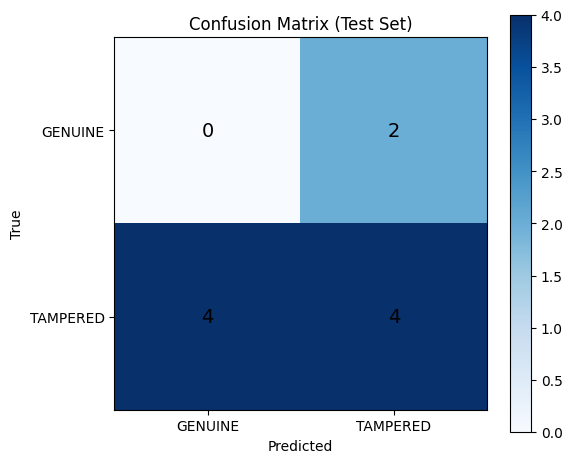

Classification Report:
              precision    recall  f1-score   support

     GENUINE       0.00      0.00      0.00         2
    TAMPERED       0.67      0.50      0.57         8

    accuracy                           0.40        10
   macro avg       0.33      0.25      0.29        10
weighted avg       0.53      0.40      0.46        10



In [11]:
import matplotlib.pyplot as plt
import numpy as np
from app.tampering.model import CLASS_NAMES

cm = eval_result.get('confusion_matrix')
if cm:
    cm_arr = np.array(cm)
    labels = [CLASS_NAMES[0], CLASS_NAMES[1]]
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm_arr, cmap='Blues')
    ax.set_xticks([0, 1]); ax.set_xticklabels(labels)
    ax.set_yticks([0, 1]); ax.set_yticklabels(labels)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.set_title('Confusion Matrix (Test Set)')
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm_arr[i, j], ha='center', va='center', fontsize=14)
    plt.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.show()

report = eval_result.get('classification_report')
if report:
    print('Classification Report:')
    print(report)
else:
    print('(classification_report unavailable — install scikit-learn)')

## Cell 12 — Single-Image Inference
> Scores are model softmax outputs — NOT fraud probabilities.

Success          : True
Predicted class  : 1
Predicted label  : TAMPERED
Score GENUINE    : 0.48141
Score TAMPERED   : 0.51859
Checkpoint epoch : 7
⚠️  WARNING: Scores are raw softmax outputs from the model, not calibrated fraud probabilities. Do not use as a standalone fraud determination. Phase 5 integration will combine this with ELA and metadata signals.


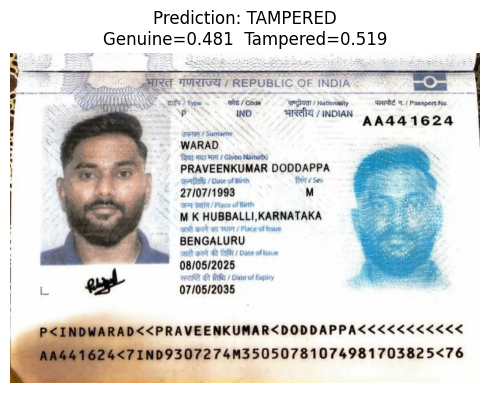

In [12]:
from app.tampering.inference import predict
from PIL import Image
import matplotlib.pyplot as plt

inf_result = predict(
    image_path      = INFERENCE_IMAGE,
    checkpoint_path = CHECKPOINT_PATH,
)

print('Success          :', inf_result['success'])
print('Predicted class  :', inf_result['predicted_class'])
print('Predicted label  :', inf_result['predicted_label'])
print('Score GENUINE    :', inf_result['score_genuine'])
print('Score TAMPERED   :', inf_result['score_tampered'])
print('Checkpoint epoch :', inf_result['checkpoint_info'].get('epoch'))

for w in inf_result['warnings']:
    print('⚠️  WARNING:', w)
for e in inf_result['errors']:
    print('❌ ERROR:', e)

# Display image
if inf_result['success'] and os.path.exists(INFERENCE_IMAGE):
    fig, ax = plt.subplots(figsize=(5, 6))
    ax.imshow(Image.open(INFERENCE_IMAGE))
    ax.set_title(
        f"Prediction: {inf_result['predicted_label']}\n"
        f"Genuine={inf_result['score_genuine']:.3f}  "
        f"Tampered={inf_result['score_tampered']:.3f}"
    )
    ax.axis('off')
    plt.tight_layout()
    plt.show()

## Cell 13 — Save Evaluation Results

In [13]:
# Results were already saved during Cell 10 (output_dir=EVAL_OUTPUT_DIR).
# This cell confirms the paths and optionally saves the training history.

import os, json

print('Evaluation results saved to:', EVAL_OUTPUT_DIR)
if os.path.isdir(EVAL_OUTPUT_DIR):
    for f in sorted(os.listdir(EVAL_OUTPUT_DIR)):
        fpath = os.path.join(EVAL_OUTPUT_DIR, f)
        print(f'  {f}  ({os.path.getsize(fpath):,} bytes)')

# Save training history as JSON
os.makedirs(EVAL_OUTPUT_DIR, exist_ok=True)
hist_path = os.path.join(EVAL_OUTPUT_DIR, 'training_history.json')
with open(hist_path, 'w') as f:
    json.dump(train_result['history'], f, indent=2)
print('\nTraining history saved to:', hist_path)

Evaluation results saved to: C:\Users\priya\Desktop\prototype\data\evaluation_results\phase3
  per_sample_predictions.csv  (1,330 bytes)
  test_evaluation.json  (565 bytes)

Training history saved to: C:\Users\priya\Desktop\prototype\data\evaluation_results\phase3\training_history.json
